## Alternative routes over a simple network
In this notebook, we set up a basic simulation where two vessels move over a 1D network path. The network is setup as a square where each edge is 100 km long. All edges are bi-directional except one. We show how each each vessel follows a different route, because of the presence of a uni-directional edge. 

In [1]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
from pyproj import Geod
from shapely.geometry import Point

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim

# OpenTNSim mixins and utils
from opentnsim.core import Identifiable, Movable
from opentnsim.core.logutils import logbook2eventtable
from opentnsim.core.utils import create_object
from opentnsim.core.visualizations import generate_vessel_gantt_chart
from opentnsim.model import Simulation
from opentnsim.graph.mixins import DiGraph
from opentnsim.graph.calculations import calculate_distance_along_path

# package(s) needed for inspecting the output
import pandas as pd


print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


#### 0. Create environment
We create the environment

In [2]:
simulation = Simulation(simulation_start = datetime.datetime(2026, 1, 1, 0, 0, 0))
env = simulation.env

#### 1. Create graph
Next, we create our graph. For this case we create a square network with four nodes and four edges, each 100 km long, one of which is uni-directional.

In [3]:
graph = DiGraph()

In [4]:
# initialize geodetic calculator with WGS84 ellipsoid
geod = Geod(ellps="WGS84")

# starting point (longitude, latitude)
lon0, lat0 = 0, 0

# compute the other three points 100 km apart to form a square
lon1, lat1, _ = geod.fwd(lon0, lat0,  0, 100000) # North from point 0
lon2, lat2, _ = geod.fwd(lon1, lat1, 90, 100000) # East from point 1
lon3, lat3, _ = geod.fwd(lon0, lat0, 90, 100000) # East from point 0

# define nodes with their geographic coordinates
coords = {
    "0": (lon0, lat0),
    "1": (lon1, lat1),
    "2": (lon2, lat2),
    "3": (lon3, lat3),
}

for node_name, coord in coords.items():
    graph.add_node(name = node_name, geometry = Point(coord))

In [5]:
# create list of edges
edges = [("0", "1"), ("1", "0"), # bi-directional edge
         ("1", "2"), ("2", "1"), # bi-directional edge
         ("2", "3"), ("3", "2"), # bi-directional edge
         ("0", "3")]             # uni-directional edge

In [6]:
# add edges
for edge in edges:
    graph.add_edge(edge)

In [7]:
# we add the graph to the environment
simulation.add_graph(graph)

#### 2. Create vessel
We create two vessels, each with their own path:

In [8]:
# make your preferred Vessel class out of available mix-ins.
Vessel = create_object(
    "Vessel", 
    (
        Identifiable, # allows to give the object a name and a random ID,
        Movable,      # allows the object to move, with a fixed speed, while logging this activity
    ), 
)

In [9]:
def mission(env, vessel):
    """
    Method that defines the mission of the vessel. 
    
    In this case: 
        keep moving along the path until its end point is reached
    """
    while True:
        yield from vessel.move()
        
        if vessel.geometry == nx.get_node_attributes(env.graph, "geometry")[vessel.route[-1]]:
            break

In [10]:
# collect paths in list
route_1 = nx.dijkstra_path(env.graph, "0", "3")
route_2 = nx.dijkstra_path(env.graph, "3", "0")
routes = [route_1, route_2]

# run a simulation for each path in the list
for index, route in enumerate(routes):
    
    # create vessel from dict 
    data_vessel = {
        "env": env,                                                  # needed for simpy simulation
        "name": "Vessel" + '_on_Path_{}'.format(index),              # required by Identifiable
        "route": route,                                              # required by Routeable
        "v": 1,                                                      # required by Movable, 1 m/s to verify distance and travel time
    }  # 
    vessel = Vessel(**data_vessel)
         
    # start the simulation
    simulation.add_vessel(vessel, mission)

#### 3. Run simulation

In [11]:
simulation.run()

#### 4. Inspect output
We can now inspect  the simulation output by inspecting the _vessel.logbook_. Note that the _Log_ mix-in was included when we added _Movable_. The _vessel.logbook_ keeps track of the moving activities of the vessel. For each discrete event OpenTNSim logs an event message, the start/stop time and the location. The _vessel.logbook_ is of type dict. For convenient inspection it can be loaded into a Pandas dataframe. 

In [12]:
for vessel_name, vessel in simulation.env.vessels.items():
    # load the logbook data into a dataframe
    df = pd.DataFrame.from_dict(vessel.logbook)
    
    print("'{}' logbook data:".format(vessel.name))  
    print('')
    
    display(df)

    trip_distance = calculate_distance_along_path(env.graph, vessel.route)
    trip_duration = datetime.timedelta.total_seconds(vessel.logbook[-1]['Timestamp'] - vessel.logbook[0]['Timestamp'])

    print("'{}' travelled a distance of {:.1f} meters".format(vessel.name, trip_distance))
    print("'{}' took {:.1f} seconds to arrive at its destination".format(vessel.name, trip_duration))  
    print("'{}' travelled at an average speed of {:.1f} meters per second".format(vessel.name, trip_distance/trip_duration))
    print('')
    print('')
    

'Vessel_on_Path_0' logbook data:



,Message,Timestamp,Value,Geometry
0,Sailing from node 0 to node 3 start,2026-01-01 00:00:00,0.0,POINT (0 0)
1,Sailing from node 0 to node 3 stop,2026-01-02 03:46:40,100000.0,POINT (0.8983152841195217 0)


'Vessel_on_Path_0' travelled a distance of 100000.0 meters
'Vessel_on_Path_0' took 100000.0 seconds to arrive at its destination
'Vessel_on_Path_0' travelled at an average speed of 1.0 meters per second


'Vessel_on_Path_1' logbook data:



,Message,Timestamp,Value,Geometry
0,Sailing from node 3 to node 2 start,2026-01-01 00:00:00.000000,0.000000,POINT (0.8983152841195217 0)
1,Sailing from node 3 to node 2 stop,2026-01-02 03:46:27.626318,99987.626318,POINT (0.8984264319755021 0.9042568124693914)
2,Sailing from node 2 to node 1 start,2026-01-02 03:46:27.626318,99987.626318,POINT (0.8984264319755021 0.9042568124693914)
3,Sailing from node 2 to node 1 stop,2026-01-03 07:33:07.626318,199987.626318,POINT (0 0.9043687229127633)
4,Sailing from node 1 to node 0 start,2026-01-03 07:33:07.626318,199987.626318,POINT (0 0.9043687229127633)
5,Sailing from node 1 to node 0 stop,2026-01-04 11:19:47.626318,299987.626318,POINT (0 0)


'Vessel_on_Path_1' travelled a distance of 299987.6 meters
'Vessel_on_Path_1' took 299987.6 seconds to arrive at its destination
'Vessel_on_Path_1' travelled at an average speed of 1.0 meters per second




The inspection of the logbook data shows that the first vessel moved from its origin (*Node 0*) directly to its destination (*Node 3*). The second vessel moved from its origin (*Node 3*) to its destination (*Node 0*), but while doing so was passing *Node 2* and *Node 1* in the process. This show that indeed the edge between *Node 0* and *Node 3* is uni-directional.

The print statements show that the length of the route from *Node 3* to *Node 3* is not exactly 300 km. This is primarily due to the fact that Edge '0 - 1' and Edge '2 - 3' are not exactly 100 km (see also the graph plot above). This is one of the issues that can occur when using coordinate projections. 

In [13]:
df_eventtable = logbook2eventtable(simulation.env.vessels.values())
df_eventtable

,object id,object name,main activity name,subactivity name,start location,stop location,start time,stop time,distance (m),duration (s)
0,1a65d25e-15c9-4626-bb91-36c5a5c5834a,Vessel_on_Path_0,Sailing from node 0 to node 3,,POINT (0 0),POINT (0.8983152841195217 0),2026-01-01 00:00:00,2026-01-02 03:46:40,100000.000000,100000.000000
1,93da8d00-a10b-463c-ab88-470a61d2a6f3,Vessel_on_Path_1,Sailing from node 3 to node 2,,POINT (0.8983152841195217 0),POINT (0.8984264319755021 0.9042568124693914),2026-01-01 00:00:00,2026-01-02 03:46:28,99987.626318,99987.626318
2,93da8d00-a10b-463c-ab88-470a61d2a6f3,Vessel_on_Path_1,Sailing from node 2 to node 1,,POINT (0.8984264319755021 0.9042568124693914),POINT (0 0.9043687229127633),2026-01-02 03:46:28,2026-01-03 07:33:08,100000.000000,100000.000000
3,93da8d00-a10b-463c-ab88-470a61d2a6f3,Vessel_on_Path_1,Sailing from node 1 to node 0,,POINT (0 0.9043687229127633),POINT (0 0),2026-01-03 07:33:08,2026-01-04 11:19:48,100000.000000,100000.000000


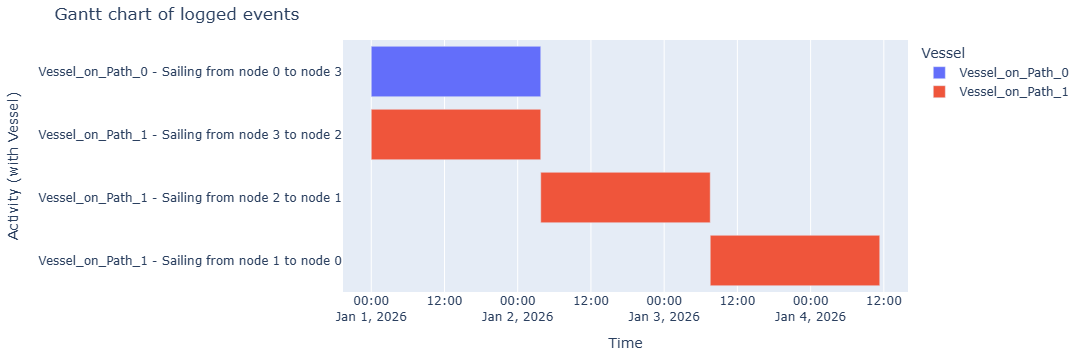

In [14]:
generate_vessel_gantt_chart(df_eventtable)